# Notebook 13 — Validation-stage Model Comparison

本 Notebook 在 Week 64–77 上比较 Logistic Regression 与 LightGBM 的三个建模阶段；模型开发与训练数据为 Week 0–63，Week 78–91 OOT 在此阶段不读取。

| 阶段 | Logistic Regression | LightGBM |
|---|---|---|
| A：历史基准 | NB7 全量原始特征与 SGD LR | NB7 全量原始特征的 LightGBM |
| B：特征筛选 | NB10 选出的 100 个 core sources，沿用基准训练配置 | NB10 选出的 500 个 features，沿用基准配置 |
| C：表示/参数优化 | NB11 Local FE 与 NB12 选定 LR 参数 | 同一 500-feature subset 与 NB12 Tree 参数 |

**比较限制：** NB7 的历史 Tree baseline 使用过 Week 64–77 进行 early stopping，因此 Tree 的 A→B 并非严格同等 Validation exposure 条件下的对照；B→C 的比较更适合用于观察该阶段参数调整带来的变化。Notebook 14 进一步记录了协议审计和后续模型选择过程。


In [1]:
#@title 第 1 步：读取项目路径与最终配置
from pathlib import Path
from collections import Counter
import gc, json, math, shutil, time, warnings, hashlib

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import lightgbm as lgb
import matplotlib.pyplot as plt

from scipy import sparse
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.preprocessing import OneHotEncoder, SplineTransformer
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/HomeCredit_Project")
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"

NB10_DIR = ARTIFACT_ROOT / "nb10" / "final"
NB11_DIR = ARTIFACT_ROOT / "nb11" / "final"
NB12_DIR = ARTIFACT_ROOT / "nb12" / "final"
NB13_DIR = ARTIFACT_ROOT / "nb13" / "final"
NB13_CKPT = ARTIFACT_ROOT / "nb13" / "checkpoints_v2"

NB13_DIR.mkdir(parents=True, exist_ok=True)
NB13_CKPT.mkdir(parents=True, exist_ok=True)

ID_COL = "case_id"
TARGET_COL = "target"
WEEK_COL = "WEEK_NUM"
SEED = 42

def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

def find_dir(required, preferred):
    required = set(required)
    for p in preferred:
        p = Path(p)
        if p.exists() and required.issubset({x.name for x in p.iterdir()}):
            return p
    first = sorted(required)[0]
    for f in PROJECT_ROOT.rglob(first):
        p = f.parent
        if required.issubset({x.name for x in p.iterdir()}):
            return p
    raise FileNotFoundError(f"找不到所需目录：{required}")

NB5_DIR = find_dir(
    {"train_clean.parquet", "validation_clean.parquet", "feature_catalog.csv"},
    [ARTIFACT_ROOT / "nb05" / "final", ARTIFACT_ROOT / "nb05", PROJECT_ROOT / "clean_split"]
)

NB7_DIR = find_dir(
    {
        "nb7_candidate_features.csv",
        "numeric_preprocessing_stats.csv",
        "categorical_encoding_rules.json",
        "validation_predictions.parquet",
        "nb7_reference_model_config.json",
    },
    [ARTIFACT_ROOT / "nb07" / "final", ARTIFACT_ROOT / "nb07", PROJECT_ROOT / "reports" / "reference_model"]
)

# 读取 NB10 / NB11 / NB12 的最终结果
nb10_rec = load_json(NB10_DIR / "nb10_recommendations.json")
tree_features = load_json(NB10_DIR / "selected_features_tree.json")

# LR 100 个 core features：优先读取 NB10 正式 freeze。
lr_core_path = NB10_DIR / "lr_core_source_features.json"
if lr_core_path.exists():
    lr_core_features = load_json(lr_core_path)
else:
    # 若当时没有正式 freeze，则从 NB9 ranking 按 NB10 推荐恢复。
    NB9_DIR = find_dir(
        {"lr_rankings.json", "tree_rankings.json", "nb9_ranking_config.json"},
        [ARTIFACT_ROOT / "nb09" / "final", ARTIFACT_ROOT / "nb09"]
    )
    lr_rankings = load_json(NB9_DIR / "lr_rankings.json")
    route = nb10_rec["lr"]["route"]
    k = int(nb10_rec["lr"]["feature_count"])
    lr_core_features = list(lr_rankings[route][:k])

lr_raw_sources = load_json(NB11_DIR / "selected_features_lr_raw_sources.json")
lr_engineered_specs = load_json(NB11_DIR / "selected_features_lr_engineered_specs.json")
lr_handoff = load_json(NB11_DIR / "lr_nb12_handoff.json")

nb12 = load_json(NB12_DIR / "nb12_dual_policy_summary.json")
lr_temporal = pd.read_csv(NB12_DIR / "lr_final_temporal_summary.csv")
tree_temporal = pd.read_csv(NB12_DIR / "tree_final_temporal_summary.csv")

lr_winner = nb12["lr_recommendations"]["AUC_MAX"]["candidate"]
tree_winner = nb12["tree_recommendations"]["AUC_MAX"]["candidate"]

# 当前这次运行中 AUC_MAX 与 ROBUST_1SE 是一致的；若以后不同，直接停下人工决定。
assert nb12["lr_recommendations"]["ROBUST_1SE"]["candidate"] == lr_winner
assert nb12["tree_recommendations"]["ROBUST_1SE"]["candidate"] == tree_winner

lr_row = lr_temporal.loc[lr_temporal["candidate"] == lr_winner].iloc[0]
tree_row = tree_temporal.loc[tree_temporal["candidate"] == tree_winner].iloc[0]

LR_TUNED = {
    "solver": str(lr_row["solver"]),
    "penalty": str(lr_row["penalty"]),
    "C": float(lr_row["C"]),
    "max_iter": 1000,
    "tol": 1e-4,
}

TREE_TUNED = {
    "learning_rate": float(tree_row["learning_rate"]),
    "num_leaves": int(tree_row["num_leaves"]),
    "min_data_in_leaf": int(tree_row["min_data_in_leaf"]),
    "feature_fraction": float(tree_row["feature_fraction"]),
    "bagging_fraction": float(tree_row["bagging_fraction"]),
    "bagging_freq": 1,
    "lambda_l1": float(tree_row["lambda_l1"]),
    "lambda_l2": float(tree_row["lambda_l2"]),
    "num_boost_round": int(tree_row["num_boost_round"]),
}

nb7_cfg = load_json(NB7_DIR / "nb7_reference_model_config.json")

LR_BASE = {
    "epochs": int(nb7_cfg["sgd_epochs"]),
    "alpha": float(nb7_cfg["sgd_alpha"]),
    "eta0": float(nb7_cfg["sgd_eta0"]),
    "average": bool(nb7_cfg.get("sgd_average", True)),
}

TREE_BASE = {
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_data_in_leaf": 20,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l1": 0.0,
    "lambda_l2": 1.0,
    "num_boost_round": int(nb7_cfg.get("lgbm_best_iteration", 300)),
}

print("最终配置")
print(f"LR core source features：{len(lr_core_features)}")
print(f"LR 最终 representation：{lr_handoff.get('final_package')}")
print("LR 调参结果：", LR_TUNED)
print(f"Tree features：{len(tree_features)}")
print("Tree 调参结果：", TREE_TUNED)
print("OOT 78–91：本册不读取")


Mounted at /content/drive
最终配置
LR core source features：100
LR 最终 representation：unary_top20__pair_top10
LR 调参结果： {'solver': 'lbfgs', 'penalty': 'l2', 'C': 0.03, 'max_iter': 1000, 'tol': 0.0001}
Tree features：500
Tree 调参结果： {'learning_rate': 0.03, 'num_leaves': 31, 'min_data_in_leaf': 20, 'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l1': 0.0, 'lambda_l2': 1.0, 'num_boost_round': 500}
OOT 78–91：本册不读取


## 2. 三阶段的含义

### 逻辑回归

```text
A 原始基准
→ NB7 全量原始特征 + 原始 SGD LR

B 特征筛选后基准
→ NB10 100 个 core features
→ 仍用 NB7 SGD 参数

C 调参后
→ NB11 Local FE
→ NB12：L2 + LBFGS + C=0.03
```

### Tree / LightGBM

```text
A 原始基准
→ NB7 全量原始特征 LGBM

B 特征筛选后基准
→ NB10 500 features
→ 仍用基准 LightGBM 参数

C 调参后
→ 同样 500 features
→ NB12 tree_slow500
```

**注意：** Tree 的 NB7 历史基准当时使用 Validation early stopping，所以 Stage A 的 Tree 分数更适合作为“历史参考”，不是完全严格的苹果对苹果比较。真正最公平的是 **B vs C**。


In [2]:
#@title Evaluation Utilities
# Shared preprocessing, model evaluation, and caching routines.

LOCAL_CACHE = Path("/content/homecredit_nb13")
LOCAL_CACHE.mkdir(parents=True, exist_ok=True)

def cache_file(src):
    src = Path(src)
    dst = LOCAL_CACHE / src.name
    if not dst.exists() or dst.stat().st_size != src.stat().st_size:
        shutil.copy2(src, dst)
    return dst

TRAIN_PATH = cache_file(NB5_DIR / "train_clean.parquet")
VALID_PATH = cache_file(NB5_DIR / "validation_clean.parquet")

train_pq = pq.ParquetFile(TRAIN_PATH)
valid_pq = pq.ParquetFile(VALID_PATH)

train_meta = pd.read_parquet(TRAIN_PATH, columns=[ID_COL, WEEK_COL, TARGET_COL])
valid_meta = pd.read_parquet(VALID_PATH, columns=[ID_COL, WEEK_COL, TARGET_COL])

assert train_meta[WEEK_COL].between(0, 63).all()
assert valid_meta[WEEK_COL].between(64, 77).all()

catalog = pd.read_csv(NB7_DIR / "nb7_candidate_features.csv")
dtype_map = catalog.set_index("feature")["dtype_family"].to_dict()

num_stats = pd.read_csv(NB7_DIR / "numeric_preprocessing_stats.csv").set_index("feature")
cat_rules_raw = load_json(NB7_DIR / "categorical_encoding_rules.json")

MISSING = "__HC_MISSING__"
RARE = "__HC_RARE__"

LR_STATE = {}

def make_lr_state(features):
    key = tuple(features)
    if key in LR_STATE:
        return LR_STATE[key]

    nums = [f for f in features if dtype_map.get(f) == "numeric"]
    cats = [f for f in features if dtype_map.get(f) in {"categorical", "boolean"}]

    st = num_stats.reindex(nums)
    med = st["median"].to_numpy(np.float32) if nums else np.array([], np.float32)
    mean = st["mean_after_imputation"].to_numpy(np.float32) if nums else np.array([], np.float32)
    scale = st["scale_after_imputation"].to_numpy(np.float32) if nums else np.array([], np.float32)
    scale[~np.isfinite(scale) | (np.abs(scale) < 1e-12)] = 1.0

    miss_feats = st.index[st["has_missing"].fillna(False).astype(bool)].tolist() if nums else []
    miss_idx = [nums.index(f) for f in miss_feats]

    cat_lists, kept = [], {}
    for f in cats:
        values = [str(x) for x in cat_rules_raw[f]]
        cat_lists.append(values)
        kept[f] = set(values)

    if cats:
        kw = dict(categories=cat_lists, handle_unknown="ignore", dtype=np.float32)
        try:
            enc = OneHotEncoder(sparse_output=True, **kw)
        except TypeError:
            enc = OneHotEncoder(sparse=True, **kw)

        dummy = pd.DataFrame({f: [cat_lists[i][0]] for i, f in enumerate(cats)})
        enc.fit(dummy)
    else:
        enc = None

    state = dict(
        features=list(features), nums=nums, cats=cats,
        med=med, mean=mean, scale=scale,
        miss_idx=miss_idx, kept=kept, enc=enc
    )
    LR_STATE[key] = state
    return state

def transform_lr(frame, state):
    n = len(frame)

    if state["nums"]:
        Xn = frame[state["nums"]].to_numpy(dtype=np.float32, na_value=np.nan)
        miss = ~np.isfinite(Xn)
        if miss.any():
            r, c = np.where(miss)
            Xn[r, c] = state["med"][c]
        Xn = (Xn - state["mean"]) / state["scale"]
        Xn = sparse.csr_matrix(Xn, dtype=np.float32)

        Xm = (
            sparse.csr_matrix(miss[:, state["miss_idx"]].astype(np.float32))
            if state["miss_idx"]
            else sparse.csr_matrix((n, 0), dtype=np.float32)
        )
    else:
        Xn = sparse.csr_matrix((n, 0), dtype=np.float32)
        Xm = sparse.csr_matrix((n, 0), dtype=np.float32)

    if state["cats"]:
        mapped = {}
        for f in state["cats"]:
            s = frame[f].astype("string").fillna(MISSING)
            s = s.where(s.isin(state["kept"][f]), RARE)
            mapped[f] = s.astype(object)
        Xc = state["enc"].transform(pd.DataFrame(mapped, index=frame.index))
    else:
        Xc = sparse.csr_matrix((n, 0), dtype=np.float32)

    return sparse.hstack([Xn, Xm, Xc], format="csr", dtype=np.float32)

def fit_sgd_selected(features):
    state = make_lr_state(features)
    model = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=LR_BASE["alpha"],
        learning_rate="constant",
        eta0=LR_BASE["eta0"],
        shuffle=False,
        average=LR_BASE["average"],
        random_state=SEED,
    )

    first = True
    for epoch in range(LR_BASE["epochs"]):
        groups = np.arange(train_pq.num_row_groups)
        np.random.default_rng(SEED + epoch).shuffle(groups)

        for rg in groups:
            frame = train_pq.read_row_group(
                int(rg),
                columns=[TARGET_COL, *features],
                use_threads=True,
            ).to_pandas()

            frame = frame.sample(
                frac=1.0,
                random_state=SEED + epoch * 1000 + int(rg),
            ).reset_index(drop=True)

            y = frame[TARGET_COL].to_numpy(np.int8)
            X = transform_lr(frame, state)

            if first:
                model.partial_fit(X, y, classes=np.array([0, 1], np.int8))
                first = False
            else:
                model.partial_fit(X, y)

            del frame, X, y
            gc.collect()

    return model, state

def predict_lr_stream(model, state, features):
    out = []
    for rg in range(valid_pq.num_row_groups):
        frame = valid_pq.read_row_group(
            rg, columns=features, use_threads=True
        ).to_pandas()
        X = transform_lr(frame, state)
        out.append(model.predict_proba(X)[:, 1].astype(np.float32))
        del frame, X
        gc.collect()
    return np.concatenate(out)

# ---------- NB11 Local FE ----------
def num_array(frame, f):
    return pd.to_numeric(frame[f], errors="coerce").to_numpy(float)

def raw_fe(frame, spec, state):
    fam, src = spec["family"], spec["sources"]

    if fam in {"signed_log1p", "winsor", "qbin", "spline"}:
        x = num_array(frame, src[0])

    if fam == "signed_log1p":
        return np.sign(x) * np.log1p(np.abs(x))
    if fam == "winsor":
        return np.clip(x, state["lower"], state["upper"])
    if fam == "ratio":
        a, b = num_array(frame, src[0]), num_array(frame, src[1])
        eps = float(spec.get("params", {}).get("epsilon", 1e-6))
        return a / np.where(np.abs(b) < eps, np.nan, b)
    if fam == "relative_change":
        a, b = num_array(frame, src[0]), num_array(frame, src[1])
        eps = float(spec.get("params", {}).get("epsilon", 1e-6))
        return (a - b) / np.maximum(np.abs(b), eps)
    if fam == "product":
        return num_array(frame, src[0]) * num_array(frame, src[1])

    raise ValueError(f"未知 Local FE：{fam}")

def fit_fe_state(frame, spec):
    fam = spec["family"]
    params = dict(spec.get("params", {}))
    src = list(spec["sources"])
    state = {"family": fam, "sources": src, "params": params}

    if fam == "winsor":
        x = num_array(frame, src[0])
        v = x[np.isfinite(x)]
        state["lower"] = float(np.quantile(v, params["lower_q"])) if len(v) else 0.0
        state["upper"] = float(np.quantile(v, params["upper_q"])) if len(v) else 0.0

    elif fam == "qbin":
        x = num_array(frame, src[0])
        v = x[np.isfinite(x)]
        if len(v):
            qs = np.linspace(0, 1, int(params["n_bins"]) + 1)[1:-1]
            edges = np.unique(np.quantile(v, qs))
        else:
            edges = np.array([])
        state["edges"] = edges.tolist()

    elif fam == "spline":
        x = num_array(frame, src[0])
        v = x[np.isfinite(x)]
        med = float(np.median(v)) if len(v) else 0.0
        x2 = np.where(np.isfinite(x), x, med).reshape(-1, 1)
        tr = SplineTransformer(
            n_knots=int(params["n_knots"]),
            degree=int(params["degree"]),
            knots="quantile",
            include_bias=False,
        )
        tr.fit(x2)
        state["median"] = med
        state["transformer"] = tr

    if fam in {"signed_log1p", "winsor", "ratio", "relative_change", "product"}:
        r = raw_fe(frame, spec, state)
        v = r[np.isfinite(r)]
        med = float(np.median(v)) if v.size else 0.0
        r2 = np.where(np.isfinite(r), r, med)
        mean = float(np.mean(r2))
        scale = float(np.std(r2))
        if not np.isfinite(scale) or scale < 1e-12:
            scale = 1.0
        state.update(out_median=med, out_mean=mean, out_scale=scale)

    return state

def transform_fe(frame, spec, state):
    fam = spec["family"]

    if fam == "qbin":
        x = num_array(frame, spec["sources"][0])
        edges = np.asarray(state["edges"], float)
        bins = np.digitize(x, edges)
        bins[~np.isfinite(x)] = len(edges) + 1
        rows = np.arange(len(frame))
        return sparse.csr_matrix(
            (np.ones(len(frame), np.float32), (rows, bins)),
            shape=(len(frame), len(edges) + 2),
            dtype=np.float32,
        )

    if fam == "spline":
        x = num_array(frame, spec["sources"][0])
        x2 = np.where(np.isfinite(x), x, state["median"]).reshape(-1, 1)
        return sparse.csr_matrix(
            state["transformer"].transform(x2).astype(np.float32)
        )

    r = raw_fe(frame, spec, state)
    r = np.where(np.isfinite(r), r, state["out_median"])
    z = ((r - state["out_mean"]) / state["out_scale"]).astype(np.float32)
    return sparse.csr_matrix(z.reshape(-1, 1))

def read_cols(pq_file, columns):
    return pd.concat(
        [
            pq_file.read_row_group(i, columns=columns, use_threads=True).to_pandas()
            for i in range(pq_file.num_row_groups)
        ],
        ignore_index=True,
    )

def build_tuned_lr_design():
    req = set(lr_raw_sources)
    for spec in lr_engineered_specs:
        req.update(spec["sources"])
    req = sorted(req)

    train_df = read_cols(train_pq, [TARGET_COL, *req])
    valid_df = read_cols(valid_pq, req)

    base_state = make_lr_state(lr_raw_sources)

    tr_blocks = [transform_lr(train_df, base_state)]
    va_blocks = [transform_lr(valid_df, base_state)]

    for spec in lr_engineered_specs:
        st = fit_fe_state(train_df, spec)
        tr_blocks.append(transform_fe(train_df, spec, st))
        va_blocks.append(transform_fe(valid_df, spec, st))

    Xtr = sparse.hstack(tr_blocks, format="csr", dtype=np.float32)
    Xva = sparse.hstack(va_blocks, format="csr", dtype=np.float32)
    ytr = train_df[TARGET_COL].to_numpy(np.int8)

    del train_df, valid_df, tr_blocks, va_blocks
    gc.collect()

    return Xtr, ytr, Xva

# ---------- Tree ----------
TREE_MISSING = "__MISSING__"
TREE_RARE = "__RARE__"
TREE_CAT_RULES = None

def tree_types():
    nums = [f for f in tree_features if dtype_map.get(f) == "numeric"]
    cats = [f for f in tree_features if dtype_map.get(f) in {"categorical", "boolean"}]
    unknown = [f for f in tree_features if f not in set(nums) | set(cats)]
    nums.extend(unknown)
    return nums, cats

def learn_tree_cat_rules():
    global TREE_CAT_RULES
    if TREE_CAT_RULES is not None:
        return TREE_CAT_RULES

    _, cats = tree_types()
    counters = {f: Counter() for f in cats}

    for rg in range(train_pq.num_row_groups):
        if not cats:
            break
        frame = train_pq.read_row_group(rg, columns=cats, use_threads=True).to_pandas()
        for f in cats:
            s = frame[f].astype("string").fillna(TREE_MISSING)
            counters[f].update({str(k): int(v) for k, v in s.value_counts().items()})
        del frame
        gc.collect()

    rules = {}
    for f in cats:
        normal = [(k, v) for k, v in counters[f].items() if k != TREE_MISSING]
        normal.sort(key=lambda x: (-x[1], x[0]))
        kept = [k for k, _ in normal[:98]]
        categories = [*kept, TREE_MISSING, TREE_RARE]
        rules[f] = {"categories": categories, "kept_set": set(categories)}

    TREE_CAT_RULES = rules
    return rules

class TreeSeq(lgb.Sequence):
    batch_size = 4096

    def __init__(self, pq_file, rules):
        self.pq_file = pq_file
        self.nums, self.cats = tree_types()
        self.features = [*self.nums, *self.cats]
        self.rules = rules
        sizes = np.array([
            pq_file.metadata.row_group(i).num_rows
            for i in range(pq_file.num_row_groups)
        ], dtype=np.int64)
        self.starts = np.concatenate([[0], np.cumsum(sizes)])
        self.total = int(self.starts[-1])
        self._rg = None
        self._mat = None

    def __len__(self):
        return self.total

    def _load(self, rg):
        frame = self.pq_file.read_row_group(
            rg, columns=self.features, use_threads=True
        ).to_pandas()

        num = (
            frame[self.nums]
            .apply(pd.to_numeric, errors="coerce")
            .to_numpy(dtype=np.float64, na_value=np.nan)
            if self.nums
            else np.empty((len(frame), 0), dtype=np.float64)
        )

        cats = []
        for f in self.cats:
            s = frame[f].astype("string").fillna(TREE_MISSING)
            rule = self.rules[f]
            s = s.where(s.isin(rule["kept_set"]), TREE_RARE)
            cats.append(
                pd.Categorical(s, categories=rule["categories"]).codes.astype(np.float64)
            )

        mat = np.hstack([num, np.column_stack(cats)]) if cats else num
        del frame
        gc.collect()
        return np.asarray(mat, np.float64, order="C")

    def _get(self, rg):
        if self._rg != rg:
            self._mat = self._load(rg)
            self._rg = rg
        return self._mat

    def _loc(self, idx):
        rg = int(np.searchsorted(self.starts[1:], idx, side="right"))
        return rg, int(idx - self.starts[rg])

    def __getitem__(self, idx):
        if isinstance(idx, (int, np.integer)):
            rg, loc = self._loc(int(idx))
            return self._get(rg)[loc]

        if isinstance(idx, slice):
            start = 0 if idx.start is None else int(idx.start)
            stop = len(self) if idx.stop is None else int(idx.stop)
            parts = []
            cur = start
            while cur < stop:
                rg, loc = self._loc(cur)
                mat = self._get(rg)
                take = min(len(mat) - loc, stop - cur)
                parts.append(mat[loc:loc + take])
                cur += take
            return parts[0] if len(parts) == 1 else np.vstack(parts)

        return np.stack([self[int(i)] for i in idx])

def fit_tree(config):
    rules = learn_tree_cat_rules()
    seq = TreeSeq(train_pq, rules)
    y = train_meta[TARGET_COL].to_numpy(np.int8)

    cat_idx = list(range(len(seq.nums), len(seq.features)))

    ds = lgb.Dataset(
        seq,
        label=y,
        feature_name=seq.features,
        categorical_feature=cat_idx,
        free_raw_data=True,
        params={
            "bin_construct_sample_cnt": 50_000,
            "max_bin": 63,
            "data_random_seed": SEED,
        },
    )

    params = {
        "objective": "binary",
        "metric": "auc",
        "learning_rate": float(config["learning_rate"]),
        "num_leaves": int(config["num_leaves"]),
        "min_data_in_leaf": int(config["min_data_in_leaf"]),
        "feature_fraction": float(config["feature_fraction"]),
        "bagging_fraction": float(config["bagging_fraction"]),
        "bagging_freq": int(config["bagging_freq"]),
        "lambda_l1": float(config["lambda_l1"]),
        "lambda_l2": float(config["lambda_l2"]),
        "seed": SEED,
        "device_type": "gpu",
        "max_bin": 63,
        "verbosity": -1,
    }

    model = lgb.train(
        params,
        ds,
        num_boost_round=int(config["num_boost_round"]),
    )

    return model, rules

def predict_tree(model, rules):
    seq = TreeSeq(valid_pq, rules)
    preds = []
    for start in range(0, len(seq), 8192):
        preds.append(model.predict(seq[start:min(start + 8192, len(seq))]))
    return np.concatenate(preds)

# ---------- checkpoint + metrics ----------
def ckpt(name, payload):
    raw = json.dumps(payload, sort_keys=True, default=str).encode()
    key = hashlib.sha256(raw).hexdigest()[:16]
    return NB13_CKPT / f"{name}__{key}.parquet"

def save_pred(path, pred):
    frame = valid_meta[[ID_COL, WEEK_COL, TARGET_COL]].copy()
    frame["prediction"] = np.asarray(pred, np.float32)
    frame.to_parquet(path, index=False)

def load_pred(path):
    return pd.read_parquet(path)

def cal_metrics(y, p):
    y = np.asarray(y, float)
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p))

    def nll(beta):
        eta = beta[0] + beta[1] * lp
        return float(np.sum(np.logaddexp(0, eta) - y * eta))

    res = minimize(nll, np.array([0.0, 1.0]), method="BFGS")
    if not res.success:
        res = minimize(nll, np.array([0.0, 1.0]), method="L-BFGS-B")

    intercept, slope = (
        (float(res.x[0]), float(res.x[1]))
        if res.success else (np.nan, np.nan)
    )

    obs = float(np.mean(y))
    exp = float(np.mean(p))

    return intercept, slope, obs / exp if exp > 0 else np.nan

def evaluate(name, frame):
    y = frame[TARGET_COL].to_numpy(np.int8)
    p = frame["prediction"].to_numpy(float)
    w = frame[WEEK_COL].to_numpy(int)

    auc = float(roc_auc_score(y, p))
    weekly = []

    for week in sorted(np.unique(w)):
        mask = w == week
        if len(np.unique(y[mask])) < 2:
            continue
        weekly.append((week, float(roc_auc_score(y[mask], p[mask]))))

    wt = pd.DataFrame(weekly, columns=["week", "auc"])
    intercept, slope, oe = cal_metrics(y, p)

    return {
        "模型": name,
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "最差周AUC": float(wt["auc"].min()),
        "周AUC标准差": float(wt["auc"].std(ddof=0)),
        "周AUC斜率": float(np.polyfit(wt["week"], wt["auc"], 1)[0]),
        "校准斜率": slope,
        "校准截距": intercept,
        "O/E": oe,
    }, wt


In [3]:
#@title 第 3 步：统一训练 / 读取六个阶段模型
preds = {}

# A：直接复用 NB7 历史 Validation prediction
hist = pd.read_parquet(NB7_DIR / "validation_predictions.parquet")

preds["LR_A_原始基准"] = (
    hist[[ID_COL, WEEK_COL, TARGET_COL, "sgd_lr_pred"]]
    .rename(columns={"sgd_lr_pred": "prediction"})
)

preds["Tree_A_原始基准"] = (
    hist[[ID_COL, WEEK_COL, TARGET_COL, "lgbm_ref_pred"]]
    .rename(columns={"lgbm_ref_pred": "prediction"})
)

# B：Feature Selection 后的基准 LR
path = ckpt(
    "LR_B_特征筛选基准",
    {"features": lr_core_features, "config": LR_BASE},
)
if path.exists():
    preds["LR_B_特征筛选基准"] = load_pred(path)
else:
    print("训练 LR 特征筛选基准...")
    model, state = fit_sgd_selected(lr_core_features)
    p = predict_lr_stream(model, state, lr_core_features)
    save_pred(path, p)
    preds["LR_B_特征筛选基准"] = load_pred(path)
    del model, state, p
    gc.collect()

# C：最终 tuned LR
path = ckpt(
    "LR_C_调参后",
    {"config": LR_TUNED, "raw": lr_raw_sources, "specs": lr_engineered_specs},
)
if path.exists():
    preds["LR_C_调参后"] = load_pred(path)
else:
    print("训练 LR 调参后模型...")
    Xtr, ytr, Xva = build_tuned_lr_design()

    model = LogisticRegression(
        solver=LR_TUNED["solver"],
        penalty=LR_TUNED["penalty"],
        C=LR_TUNED["C"],
        max_iter=LR_TUNED["max_iter"],
        tol=LR_TUNED["tol"],
        random_state=SEED,
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(Xtr, ytr)

    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        print("提示：最终 LR 出现收敛警告，请在结果解释时保留。")

    p = model.predict_proba(Xva)[:, 1]
    save_pred(path, p)
    preds["LR_C_调参后"] = load_pred(path)

    del model, p
    gc.collect()

# B：Feature Selection 后的基准 Tree
path = ckpt(
    "Tree_B_特征筛选基准",
    {"features": tree_features, "config": TREE_BASE},
)
if path.exists():
    preds["Tree_B_特征筛选基准"] = load_pred(path)
else:
    print("训练 Tree 特征筛选基准...")
    model, rules = fit_tree(TREE_BASE)
    p = predict_tree(model, rules)
    save_pred(path, p)
    preds["Tree_B_特征筛选基准"] = load_pred(path)
    del model, p
    gc.collect()

# C：最终 tuned Tree
path = ckpt(
    "Tree_C_调参后",
    {"features": tree_features, "config": TREE_TUNED},
)
if path.exists():
    preds["Tree_C_调参后"] = load_pred(path)
else:
    print("训练 Tree 调参后模型...")
    model, rules = fit_tree(TREE_TUNED)
    p = predict_tree(model, rules)
    save_pred(path, p)
    preds["Tree_C_调参后"] = load_pred(path)
    del model, p
    gc.collect()

print("六个阶段模型已准备完成。")


训练 LR 特征筛选基准...
训练 LR 调参后模型...
训练 Tree 特征筛选基准...
[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
训练 Tree 调参后模型...
六个阶段模型已准备完成。


In [4]:
#@title 第 4 步：统一评价并比较三阶段
rows = []
weekly_tables = {}

for name, frame in preds.items():
    row, weekly = evaluate(name, frame)
    rows.append(row)
    weekly_tables[name] = weekly

result = pd.DataFrame(rows)

order = [
    "LR_A_原始基准",
    "LR_B_特征筛选基准",
    "LR_C_调参后",
    "Tree_A_原始基准",
    "Tree_B_特征筛选基准",
    "Tree_C_调参后",
]
result["顺序"] = result["模型"].map({k: i for i, k in enumerate(order)})
result = result.sort_values("顺序").drop(columns="顺序").reset_index(drop=True)

display(result)

# 分解 A→B 与 B→C 的 AUC 增量
def auc_of(name):
    return float(result.loc[result["模型"] == name, "AUC"].iloc[0])

increment = pd.DataFrame([
    {
        "模型家族": "逻辑回归",
        "原始基准AUC": auc_of("LR_A_原始基准"),
        "特征筛选后AUC": auc_of("LR_B_特征筛选基准"),
        "调参后AUC": auc_of("LR_C_调参后"),
        "Feature Selection增量": auc_of("LR_B_特征筛选基准") - auc_of("LR_A_原始基准"),
        "后续调参增量": auc_of("LR_C_调参后") - auc_of("LR_B_特征筛选基准"),
    },
    {
        "模型家族": "Tree",
        "原始基准AUC": auc_of("Tree_A_原始基准"),
        "特征筛选后AUC": auc_of("Tree_B_特征筛选基准"),
        "调参后AUC": auc_of("Tree_C_调参后"),
        "Feature Selection增量": auc_of("Tree_B_特征筛选基准") - auc_of("Tree_A_原始基准"),
        "后续调参增量": auc_of("Tree_C_调参后") - auc_of("Tree_B_特征筛选基准"),
    },
])

display(increment)


,模型,AUC,Gini,最差周AUC,周AUC标准差,周AUC斜率,校准斜率,校准截距,O/E
0,LR_A_原始基准,0.737423,0.474846,0.668243,0.043771,-0.005739,0.436589,-1.859742,0.860858
1,LR_B_特征筛选基准,0.790034,0.580067,0.720676,0.029537,0.002226,0.939095,-0.644686,0.647727
2,LR_C_调参后,0.807631,0.615262,0.749007,0.028469,0.002998,0.925633,-1.183860,0.407729
3,Tree_A_原始基准,0.852679,0.705358,0.793536,0.024590,0.002655,0.994841,-0.504755,0.651484
4,Tree_B_特征筛选基准,0.848245,0.696491,0.785705,0.025584,0.002956,1.002492,-0.515729,0.633648
5,Tree_C_调参后,0.848293,0.696585,0.798941,0.022907,0.002761,1.070450,-0.379190,0.616190


,模型家族,原始基准AUC,特征筛选后AUC,调参后AUC,Feature Selection增量,后续调参增量
0,逻辑回归,0.737423,0.790034,0.807631,0.052610,0.017597
1,Tree,0.852679,0.848245,0.848293,-0.004434,0.000047


/tmp/ipykernel_3514/1197288662.py:14: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3514/1197288662.py:14: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3514/1197288662.py:14: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3514/1197288662.py:14: UserWarning: Glyph 20934 (\N{CJK UNIFIED IDEOGRAPH-51C6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3514/1197288662.py:14: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3514/1197288662.py:14: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3514/1197288662.py:14: UserWarning: Glyph 31579 (\N{CJK UNIFIED IDEOGRAPH-7B5B}

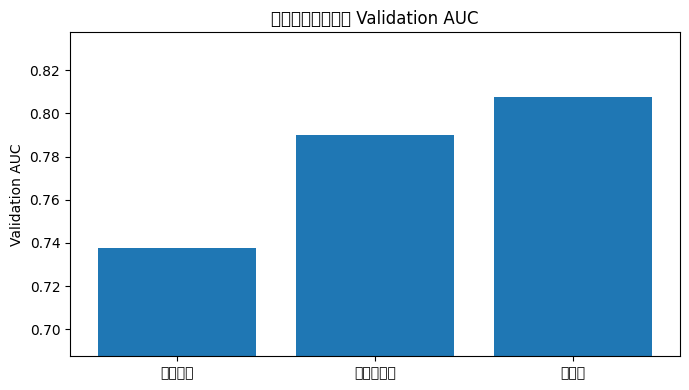

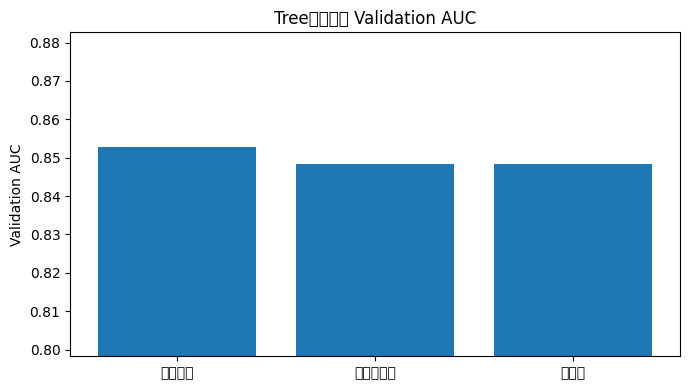

结果已保存： /content/drive/MyDrive/HomeCredit_Project/artifacts/nb13/final
OOT 78–91：未读取


In [5]:
#@title 第 5 步：画图并保存结果
for family, names in {
    "逻辑回归": ["LR_A_原始基准", "LR_B_特征筛选基准", "LR_C_调参后"],
    "Tree": ["Tree_A_原始基准", "Tree_B_特征筛选基准", "Tree_C_调参后"],
}.items():
    values = [auc_of(x) for x in names]
    labels = ["原始基准", "特征筛选后", "调参后"]

    plt.figure(figsize=(7, 4))
    plt.bar(labels, values)
    plt.ylabel("Validation AUC")
    plt.title(f"{family}：三阶段 Validation AUC")
    plt.ylim(max(0.5, min(values) - 0.05), min(1.0, max(values) + 0.03))
    plt.tight_layout()
    plt.show()

result.to_csv(NB13_DIR / "三阶段验证结果.csv", index=False)
increment.to_csv(NB13_DIR / "三阶段AUC增量.csv", index=False)

all_pred = valid_meta[[ID_COL, WEEK_COL, TARGET_COL]].copy()
for name, frame in preds.items():
    mapping = frame.set_index(ID_COL)["prediction"]
    all_pred[name] = all_pred[ID_COL].map(mapping)

all_pred.to_parquet(NB13_DIR / "三阶段Validation预测.parquet", index=False)

print("结果已保存：", NB13_DIR)
print("OOT 78–91：未读取")


## 6. 验证集结果与解释

本次已保存输出显示：

| Model Family | Baseline AUC (A) | Feature Selection AUC (B) | Tuned AUC (C) | A→B | B→C |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.737423 | 0.790034 | 0.807631 | +0.052610 | +0.017597 |
| LightGBM | 0.852679 | 0.848245 | 0.848293 | −0.004434 | +0.000047 |

这些数值来自保存的 Validation Week 64–77 运行表，未重新执行实验。Logistic Regression 在该对比下显示明显的阶段提升；LightGBM 的 B→C 增益很小，且历史 baseline A 使用过 Validation early stopping，因此不应将 A→B 的差异简单归因于特征筛选效果。

后续需要控制不同实验的 Validation exposure，并在选定模型后利用尚未参与选择的 OOT 时间窗口检查时间泛化能力。总体 AUC 之外，最差周 AUC、周波动、概率校准和模型复杂度也应分别呈现。
